# Joint shape and uncertain-view reconstruction

## 1. Problem and observations

Eight silhouettes hide interior/concavity information; uncertain orientations couple shape and camera recovery. We reconstruct the complete128³density and8orientations, using the supplied angular readings to anchor the world frame. All outputs below are freshly computed by local source; reproduced original measurements and actual synthetic truth are separate comparisons. No hidden object or true orientation initializes reconstruction.

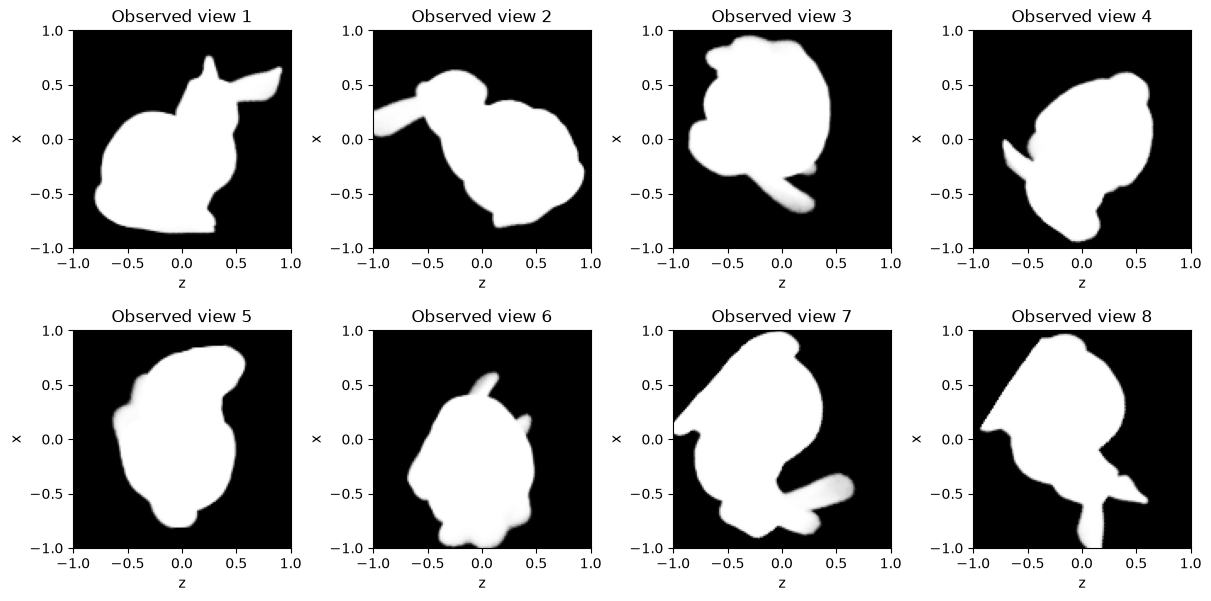

Runtime: 3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)] 2.9.1+cu128 NVIDIA GeForce RTX 4080 SUPER


In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json,subprocess,ctypes,os
os.environ['CUBLAS_WORKSPACE_CONFIG']=':4096:8'
import numpy as np
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
torch.set_num_threads(1)
try:torch.set_num_interop_threads(1)
except RuntimeError:pass
from src.preprocessing import load_observations
from src.main import run
from src.solvers import reconstruct
from src.physics_model import carve,project
from src.visualization import density_metrics,pose_errors,plot_surface
images,prior=load_observations(ROOT/'data/raw_data.npz')
with np.load(ROOT/'evaluation/ground_truth.npz') as z:truth=z['reconstruction'][0];true_views=z['viewpoints'][0]
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz') as z:original={k:z[k] for k in z.files}
with np.load(ROOT/'notebooks/reference_outputs/carving_measurements.npz') as z:native_carve={k:z[k] for k in z.files}
fig,ax=plt.subplots(2,4,figsize=(12,6),constrained_layout=True)
for i,a in enumerate(ax.flat):a.imshow(images[:,:,i],origin='lower',extent=[-1,1,-1,1],vmin=0,vmax=1,cmap='gray');a.set(title=f'Observed view {i+1}',xlabel='z',ylabel='x')
plt.show()
print('Runtime:',sys.version,torch.__version__,torch.cuda.get_device_name())


## 2. Forward model, regularization and active full inversion

The selected model rotates row coordinates by $R_zR_yR_x$, uses explicit eight-corner interpolation and opacity $1-\exp(-0.5\sum_y\rho)$. Inclusive normalized coordinates and the source half-voxel mapping are retained. Its floor/ceil interpolation gives zero weights at exact integer knots, including clamped boundaries; this is an explicitly preserved source artifact.

A full five-scale3Dconvolutional generator maps fixed Gaussian noise to sigmoid density. All generator weights and Euler angles are learned jointly for500Adam updates with mean absolute opacity residual minus0.1mean cosine angular agreement. The negative sign follows the circular prior and source code; the printed paper's plus sign is inconsistent. Selected code uses LeakyReLU0.2. DeterministicCUDAflags remove the measured Conv3dbackward nondeterminism; they do not change model, observations or update count. The native saved density is before the final update, saved angles after it; recomputed final-pose residual is labelled separately.

25 /500 opacityMAE 0.5487174987792969
50 /500 opacityMAE 0.25182482600212097
75 /500 opacityMAE 0.06821247190237045
100 /500 opacityMAE 0.032136447727680206
125 /500 opacityMAE 0.015509083867073059
150 /500 opacityMAE 0.013531874865293503
175 /500 opacityMAE 0.011286132037639618
200 /500 opacityMAE 0.01017683744430542
225 /500 opacityMAE 0.008322222158312798
250 /500 opacityMAE 0.0068117426708340645
275 /500 opacityMAE 0.007558272685855627
300 /500 opacityMAE 0.005726201459765434
325 /500 opacityMAE 0.005821503698825836
350 /500 opacityMAE 0.005128900054842234
375 /500 opacityMAE 0.0049420977011322975
400 /500 opacityMAE 0.00404327642172575
425 /500 opacityMAE 0.005046825855970383
450 /500 opacityMAE 0.003840141464024782
475 /500 opacityMAE 0.004591474309563637
500 /500 opacityMAE 0.004437657073140144
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "density_ncc": 0.9249522711984658,
    "density_nrmse": 0.13375902063612427,
    "occupancy_iou": 0.8282710573589154,
    "view_

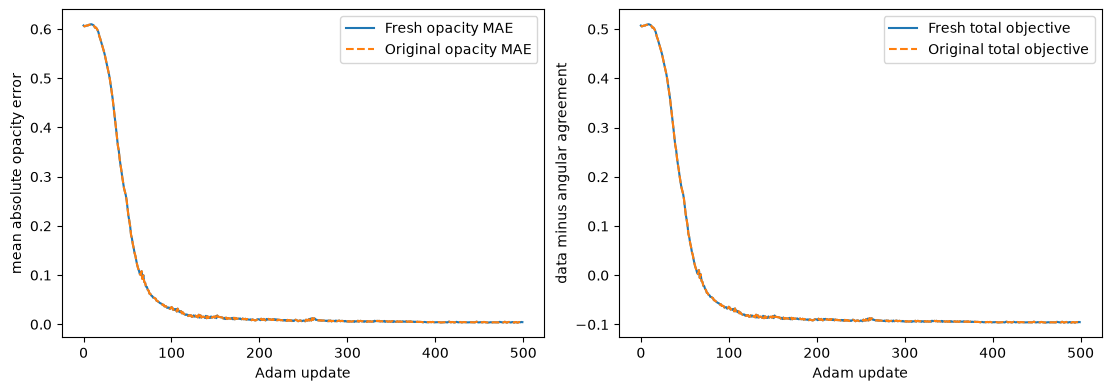

In [2]:
class MemoryStatus(ctypes.Structure):
    _fields_=[('length',ctypes.c_ulong),('load',ctypes.c_ulong)]+[(s,ctypes.c_ulonglong) for s in ['total_phys','avail_phys','total_page','avail_page','total_virt','avail_virt','extended']]
def guard(iteration,row):
    if iteration%25==0:
        status=MemoryStatus();status.length=ctypes.sizeof(status);ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(status))
        assert min(status.avail_phys,status.avail_page)>=6.25*1024**3,'Host resource guard'
        assert torch.cuda.mem_get_info()[0]>=2*1024**3,'GPU resource guard'
        print(iteration,'/500 opacityMAE',row[0])
volume,views,history,info=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz',callback=guard)
execution=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert execution.returncode==0,execution.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text());print(json.dumps(report,indent=2));print('Fresh full500seconds',info['runtime_seconds'])
fresh_metrics=density_metrics(volume,truth);native_metrics=density_metrics(original['output_reconstruction'],truth)
fig,ax=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
ax[0].plot(history[:,0],label='Fresh opacity MAE');ax[0].plot(original['output_losses'][:,0],'--',label='Original opacity MAE');ax[0].set(xlabel='Adam update',ylabel='mean absolute opacity error');ax[0].legend()
ax[1].plot(history[:,1],label='Fresh total objective');ax[1].plot(original['output_losses'][:,1],'--',label='Original total objective');ax[1].set(xlabel='Adam update',ylabel='data minus angular agreement');ax[1].legend();plt.show()


## 3. Actual truth, reproduced method and fresh geometry

Actual density and true camera orientations come from independent source generation; they are not a reconstruction relabelled as truth. Three-dimensional panels show boundary voxel centers, thinned only for display, in a shared fixed normalized frame. All metrics use the complete arrays. No free rotation, reflection or scale is fitted to the target.

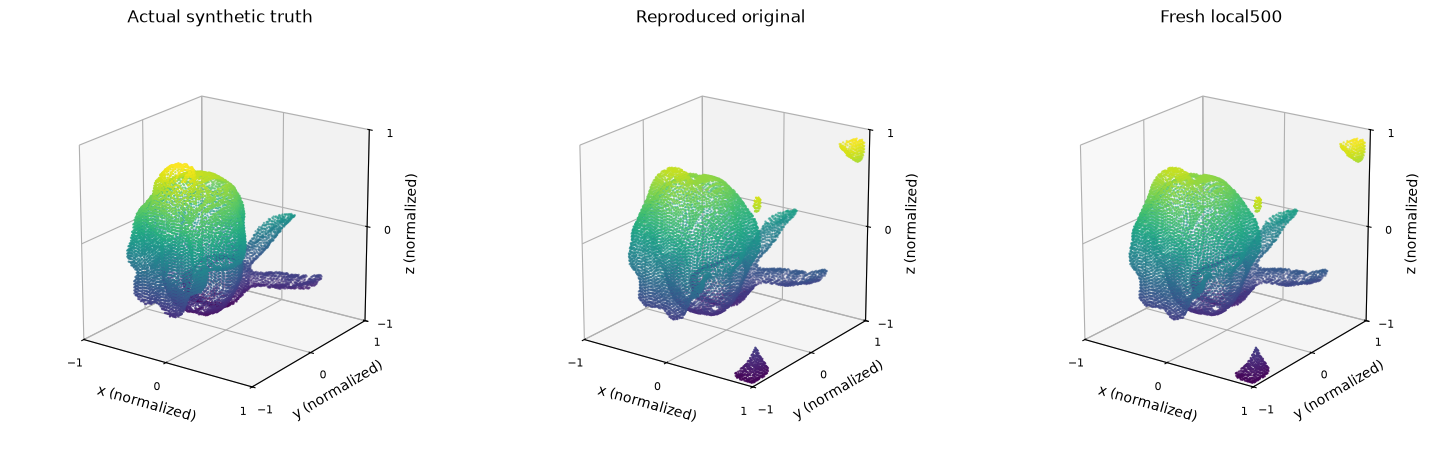

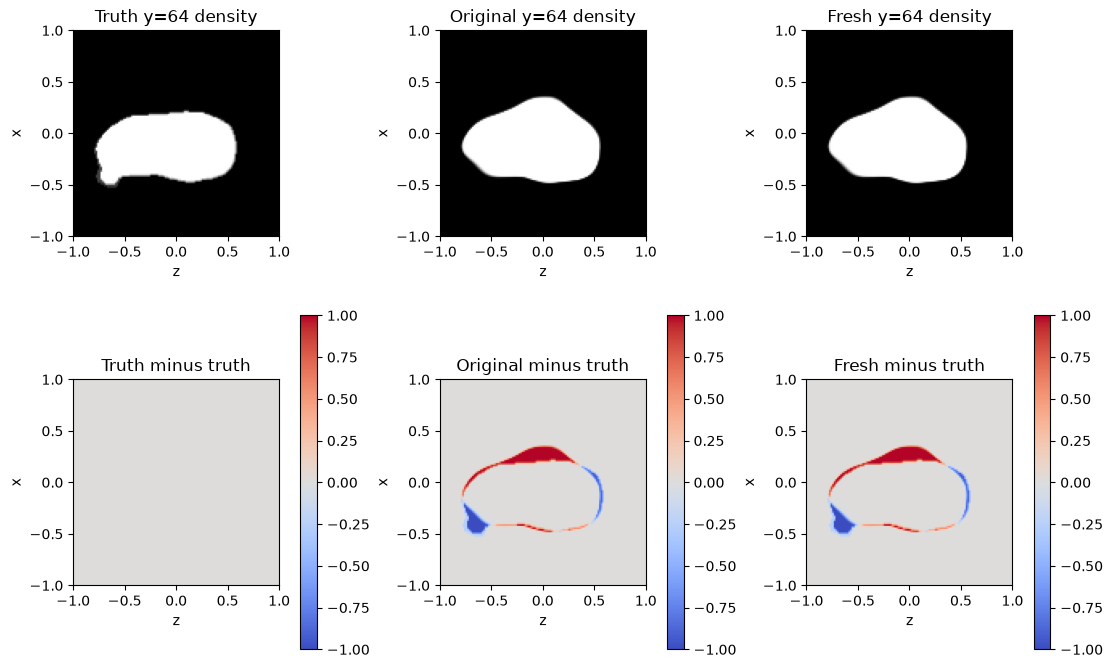

Original vs truth {'ncc': 0.9249522711985257, 'nrmse': 0.13375902063612427, 'iou': 0.8282710573589154} fresh vs truth {'ncc': 0.9249522711985257, 'nrmse': 0.13375902063612427, 'iou': 0.8282710573589154} fresh vs original {'ncc': 1.0, 'nrmse': 0.0, 'iou': 1.0}


In [3]:
fig=plt.figure(figsize=(15,4.5),constrained_layout=True)
for i,(v,label) in enumerate([(truth,'Actual synthetic truth'),(original['output_reconstruction'],'Reproduced original'),(volume,'Fresh local500')]):plot_surface(fig.add_subplot(1,3,i+1,projection='3d'),v,label)
for a in fig.axes:
    a.set_box_aspect((1,1,1),zoom=.82);a.set(xticks=[-1,0,1],yticks=[-1,0,1],zticks=[-1,0,1]);a.tick_params(labelsize=8)
plt.show()
fig,ax=plt.subplots(2,3,figsize=(11,7),constrained_layout=True)
for j,(v,label) in enumerate([(truth,'Truth'),(original['output_reconstruction'],'Original'),(volume,'Fresh')]):
    ax[0,j].imshow(v[:,64,:],origin='lower',extent=[-1,1,-1,1],vmin=0,vmax=1,cmap='gray');ax[0,j].set(title=label+' y=64 density',xlabel='z',ylabel='x')
    delta=v-truth;bound=max(float(np.max(np.abs(volume-truth))),1e-9);im=ax[1,j].imshow(delta[:,64,:],origin='lower',extent=[-1,1,-1,1],vmin=-bound,vmax=bound,cmap='coolwarm');fig.colorbar(im,ax=ax[1,j]);ax[1,j].set(title=label+' minus truth',xlabel='z',ylabel='x')
plt.show()
print('Original vs truth',native_metrics,'fresh vs truth',fresh_metrics,'fresh vs original',density_metrics(volume,original['output_reconstruction']))


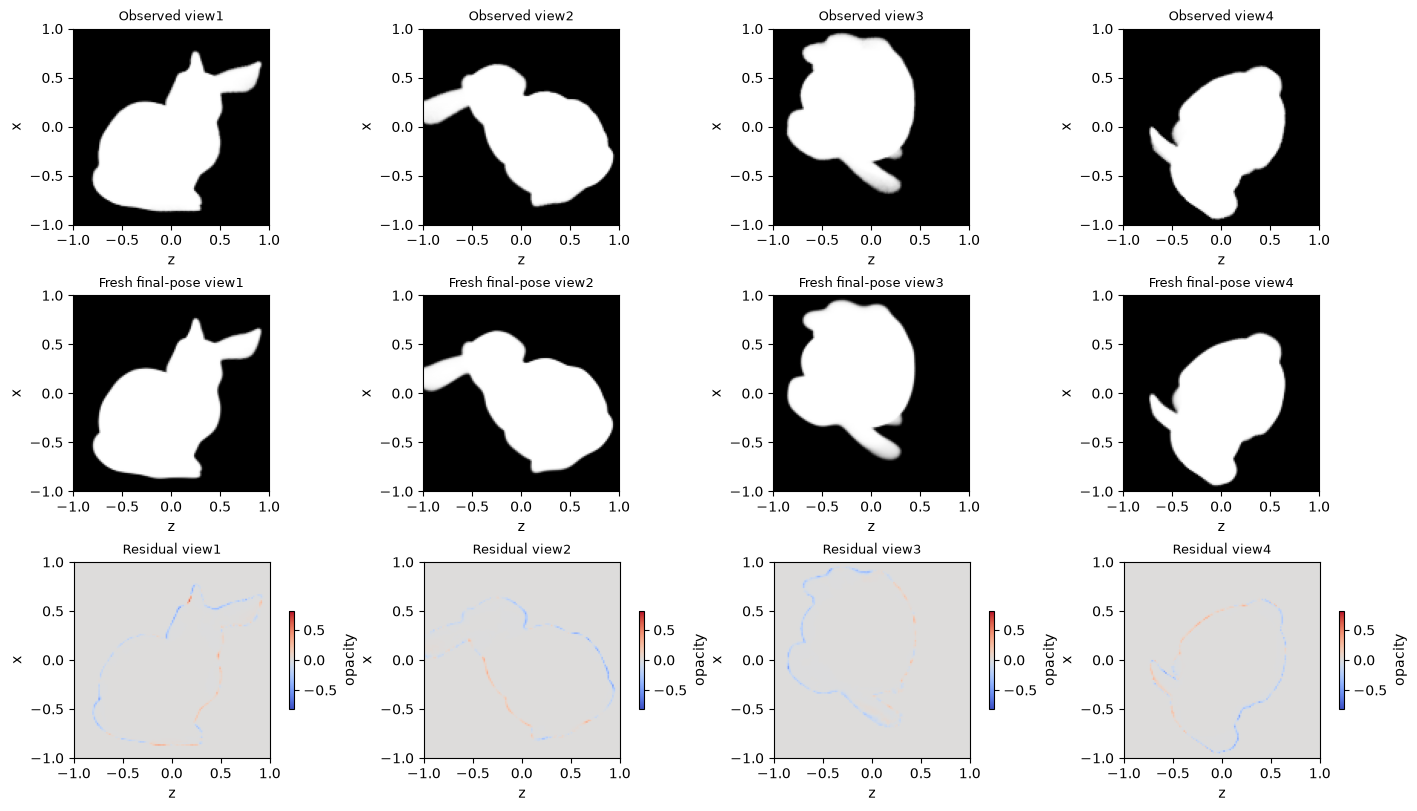

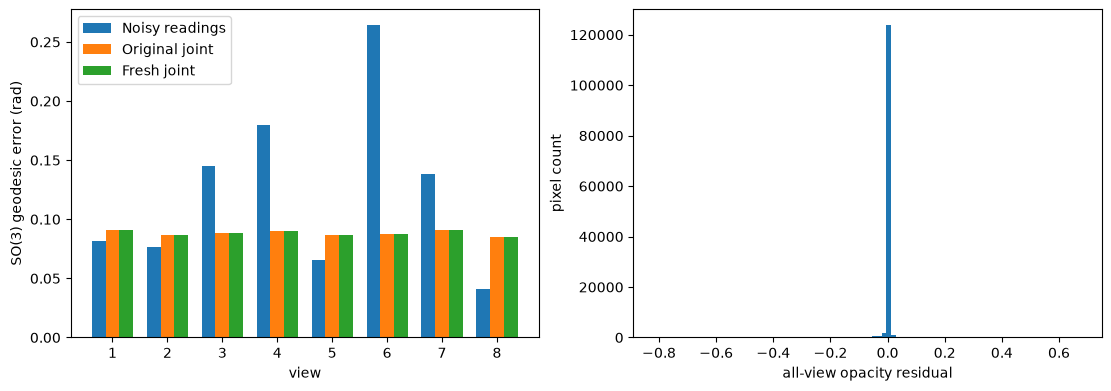

Loop saved-projection MAE 0.004437657073140144 recomputed saved-density/final-view MAE 0.004405859


In [4]:
with torch.no_grad():fresh_projection=project(torch.tensor(volume,device='cuda'),torch.tensor(views)).cpu().numpy()
delta=fresh_projection-images;bound=max(float(np.max(np.abs(delta))),1e-9)
fig,ax=plt.subplots(3,4,figsize=(14,8),constrained_layout=True)
for j in range(4):
    for row,(v,label) in enumerate([(images,'Observed'),(fresh_projection,'Fresh final-pose'),(delta,'Residual')]):
        im=ax[row,j].imshow(v[:,:,j],origin='lower',extent=[-1,1,-1,1],vmin=-bound if row==2 else 0,vmax=bound if row==2 else 1,cmap='coolwarm' if row==2 else 'gray');ax[row,j].set(title=f'{label} view{j+1}',xlabel='z',ylabel='x')
        ax[row,j].title.set_fontsize(9)
        if row==2:fig.colorbar(im,ax=ax[row,j],label='opacity',shrink=.5,pad=.04)
plt.show()
error_prior=pose_errors(prior,true_views);error_native=pose_errors(original['output_views'],true_views);error_fresh=pose_errors(views,true_views)
fig,ax=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True);idx=np.arange(8)
for shift,values,label in [(-.25,error_prior,'Noisy readings'),(0,error_native,'Original joint'),(.25,error_fresh,'Fresh joint')]:ax[0].bar(idx+shift,values,.25,label=label)
ax[0].set(xticks=idx,xticklabels=idx+1,xlabel='view',ylabel='SO(3) geodesic error (rad)');ax[0].legend()
ax[1].hist(delta.ravel(),bins=90);ax[1].set(xlabel='all-view opacity residual',ylabel='pixel count');plt.show()
print('Loop saved-projection MAE',history[-1,0],'recomputed saved-density/final-view MAE',np.mean(np.abs(delta)))


## 4. Original carving and privileged comparison

Keep both scientific comparison groups: sequential Carving uses only the uncertain supplied views, while Carving* uses actual true views and is privileged. True views are unavailable to the solver. Both run freshly through local explicit operators and compare with independent original captures. Repeated rotation/interpolation is part of this source baseline. The prior can improve ambiguity handling, but no claim that every deep result dominates every privileged baseline is assumed.

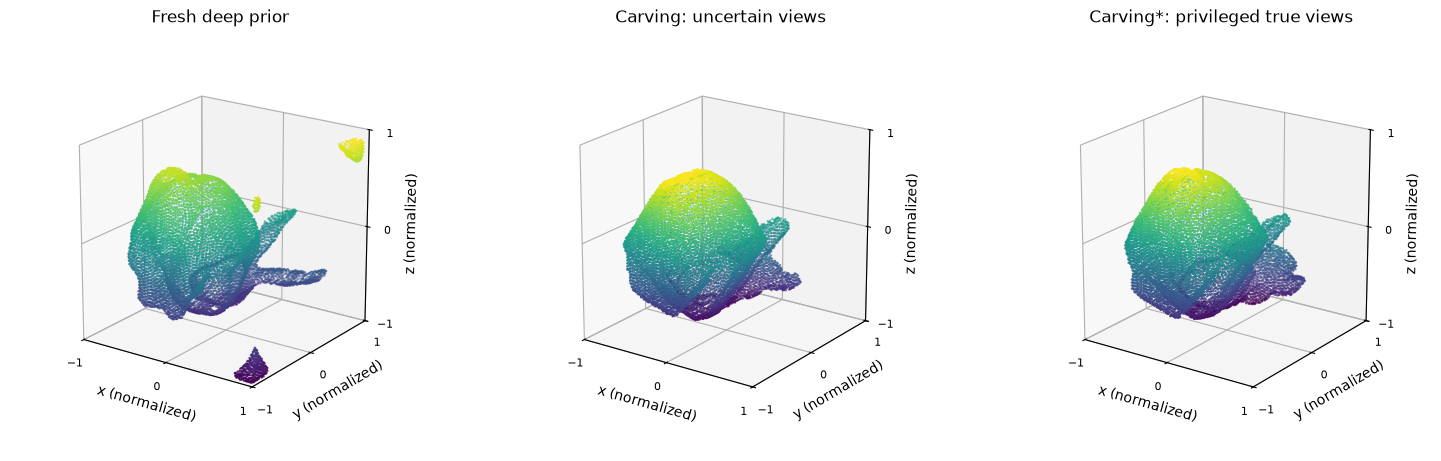

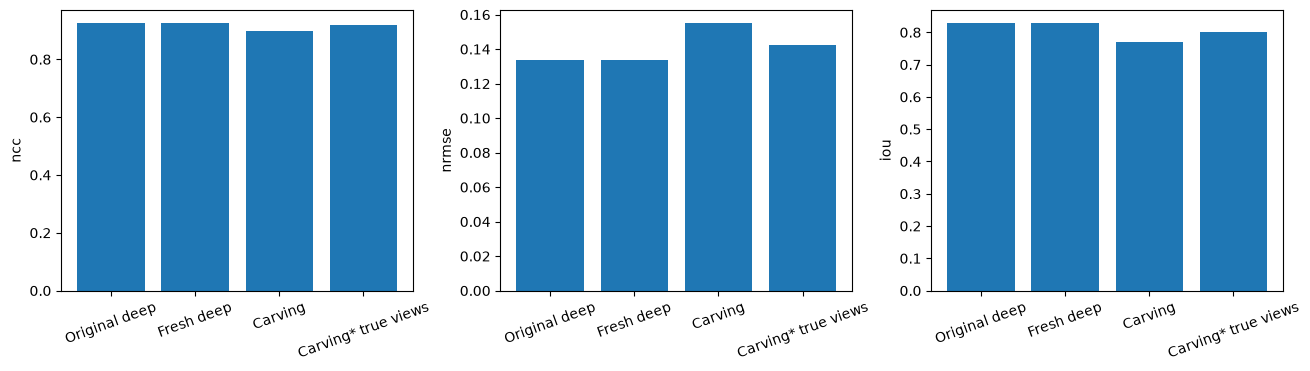

{
  "Original deep": {
    "ncc": 0.9249522711985257,
    "nrmse": 0.13375902063612427,
    "iou": 0.8282710573589154
  },
  "Fresh deep": {
    "ncc": 0.9249522711985257,
    "nrmse": 0.13375902063612427,
    "iou": 0.8282710573589154
  },
  "Carving": {
    "ncc": 0.8984152868246911,
    "nrmse": 0.1550186439871569,
    "iou": 0.769544836445884
  },
  "Carving* true views": {
    "ncc": 0.9178294844593193,
    "nrmse": 0.14258465820630875,
    "iou": 0.8004269516591368
  }
}


In [5]:
carving=carve(images,prior);carving_star=carve(images,true_views)
for label,value in [('noisy',carving),('true',carving_star)]:np.testing.assert_array_equal(value,native_carve['output_'+label+'_volume'])
comparisons={'Original deep':native_metrics,'Fresh deep':fresh_metrics,'Carving':density_metrics(carving,truth),'Carving* true views':density_metrics(carving_star,truth)}
fig=plt.figure(figsize=(15,4.5),constrained_layout=True)
for i,(v,label) in enumerate([(volume,'Fresh deep prior'),(carving,'Carving: uncertain views'),(carving_star,'Carving*: privileged true views')]):plot_surface(fig.add_subplot(1,3,i+1,projection='3d'),v,label)
for a in fig.axes:
    a.set_box_aspect((1,1,1),zoom=.82);a.set(xticks=[-1,0,1],yticks=[-1,0,1],zticks=[-1,0,1]);a.tick_params(labelsize=8)
plt.show()
fig,ax=plt.subplots(1,3,figsize=(13,3.6),constrained_layout=True)
for a,key in zip(ax,['ncc','nrmse','iou']):a.bar(range(4),[m[key] for m in comparisons.values()]);a.set(xticks=range(4),xticklabels=list(comparisons),ylabel=key);a.tick_params(axis='x',rotation=20)
plt.show();print(json.dumps(comparisons,indent=2));torch.cuda.empty_cache()


## 5. Full-path ablation and replicated robustness

Remove angular regularization but retain the complete network,128³grid, eight silhouettes and500updates. This is a labelled ablation, not the selected benchmark. Separately add hypothetical independent angular-reading perturbations with standard deviations0.03and0.08rad; two independent realizations per level each undergo a new complete500update joint reconstruction. The same training seed controls initialization, isolating reading sensitivity. Perturbations are not calibrated uncertainties or additional true observations; the bound Judge thresholds remain unchanged.

25 /500 opacityMAE 0.5537824630737305
50 /500 opacityMAE 0.29488131403923035
75 /500 opacityMAE 0.08139365911483765
100 /500 opacityMAE 0.04357021301984787
125 /500 opacityMAE 0.029942844063043594
150 /500 opacityMAE 0.02077052742242813
175 /500 opacityMAE 0.014983545057475567
200 /500 opacityMAE 0.00982220470905304
225 /500 opacityMAE 0.00934782437980175
250 /500 opacityMAE 0.009003480896353722
275 /500 opacityMAE 0.007525105960667133
300 /500 opacityMAE 0.009143419563770294
325 /500 opacityMAE 0.007929307408630848
350 /500 opacityMAE 0.007564208935946226
375 /500 opacityMAE 0.005460634827613831
400 /500 opacityMAE 0.005508314352482557
425 /500 opacityMAE 0.0046904850751161575
450 /500 opacityMAE 0.00409409636631608
475 /500 opacityMAE 0.004215386230498552
500 /500 opacityMAE 0.004901288077235222


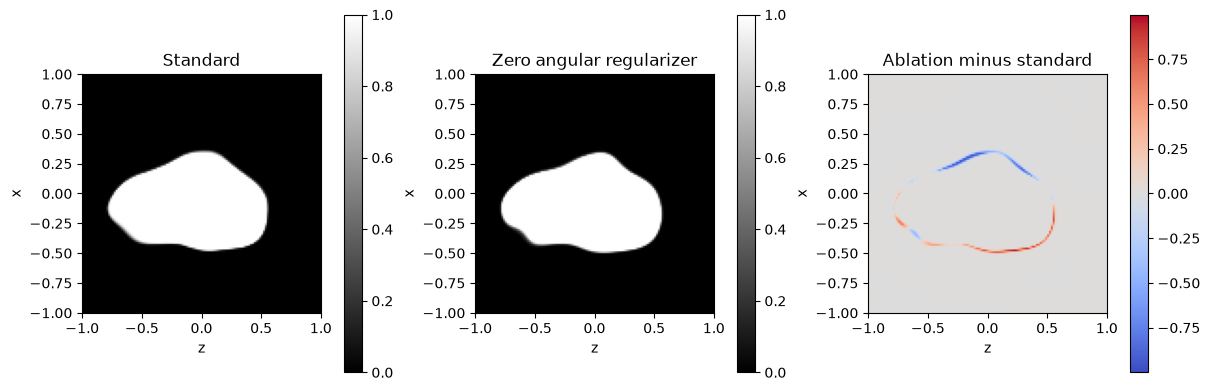

Ablation {'ncc': 0.9169699733617387, 'nrmse': 0.14043033413092396, 'iou': 0.8176237503266243} poseRMSE 0.10247859626543103
25 /500 opacityMAE 0.540083646774292
50 /500 opacityMAE 0.17800375819206238
75 /500 opacityMAE 0.07043860852718353
100 /500 opacityMAE 0.0401402972638607
125 /500 opacityMAE 0.027114082127809525
150 /500 opacityMAE 0.017970865592360497
175 /500 opacityMAE 0.014484265819191933
200 /500 opacityMAE 0.00979926623404026
225 /500 opacityMAE 0.009128672070801258
250 /500 opacityMAE 0.006971503607928753
275 /500 opacityMAE 0.006563812494277954
300 /500 opacityMAE 0.006285530049353838
325 /500 opacityMAE 0.005200671032071114
350 /500 opacityMAE 0.005503838881850243
375 /500 opacityMAE 0.005133455619215965
400 /500 opacityMAE 0.0037585662212222815
425 /500 opacityMAE 0.004669861868023872
450 /500 opacityMAE 0.004027398768812418
475 /500 opacityMAE 0.005267698783427477
500 /500 opacityMAE 0.003847579937428236
25 /500 opacityMAE 0.5415061712265015
50 /500 opacityMAE 0.21870213

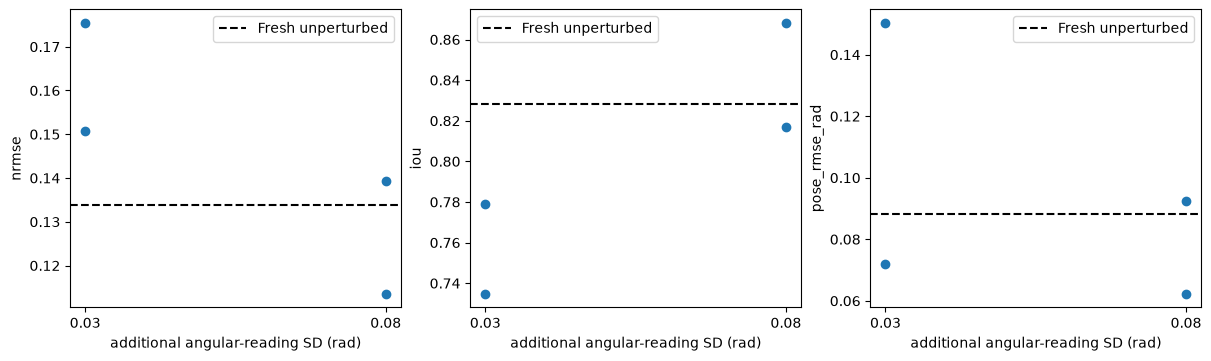

{
  "fresh_seconds": 254.68528819998028,
  "native": {
    "ncc": 0.9249522711985257,
    "nrmse": 0.13375902063612427,
    "iou": 0.8282710573589154
  },
  "fresh": {
    "ncc": 0.9249522711985257,
    "nrmse": 0.13375902063612427,
    "iou": 0.8282710573589154
  },
  "fresh_pose_rmse_rad": 0.08827940115932996,
  "fresh_pose_max_rad": 0.09090911674600045,
  "full_parity": {
    "ncc": 1.0,
    "nrmse": 0.0,
    "iou": 1.0
  },
  "saved_loop_opacity_mae": 0.004437657073140144,
  "recomputed_final_pose_opacity_mae": 0.004405858926475048,
  "carving": {
    "Original deep": {
      "ncc": 0.9249522711985257,
      "nrmse": 0.13375902063612427,
      "iou": 0.8282710573589154
    },
    "Fresh deep": {
      "ncc": 0.9249522711985257,
      "nrmse": 0.13375902063612427,
      "iou": 0.8282710573589154
    },
    "Carving": {
      "ncc": 0.8984152868246911,
      "nrmse": 0.1550186439871569,
      "iou": 0.769544836445884
    },
    "Carving* true views": {
      "ncc": 0.9178294844593193

In [6]:
ablated,ablated_views,ablation_history,ablation_info=reconstruct(images,prior,view_weight=0.,callback=guard)
ablation_metrics=density_metrics(ablated,truth);ablation_pose=pose_errors(ablated_views,true_views)
fig,ax=plt.subplots(1,3,figsize=(12,3.8),constrained_layout=True)
for i,(v,label) in enumerate([(volume,'Standard'),(ablated,'Zero angular regularizer'),(ablated-volume,'Ablation minus standard')]):
    bound=max(float(np.max(np.abs(ablated-volume))),1e-9);im=ax[i].imshow(v[:,64,:],origin='lower',extent=[-1,1,-1,1],cmap='coolwarm' if i==2 else 'gray',vmin=-bound if i==2 else 0,vmax=bound if i==2 else 1);ax[i].set(title=label,xlabel='z',ylabel='x');fig.colorbar(im,ax=ax[i])
plt.show();print('Ablation',ablation_metrics,'poseRMSE',np.sqrt(np.mean(ablation_pose**2)));torch.cuda.empty_cache()
robustness=[]
for sigma in [.03,.08]:
    for replicate in range(2):
        perturbed=(prior+np.random.default_rng(1000+int(sigma*1000)+replicate).normal(0,sigma,prior.shape)).astype(np.float32)
        result,angles,losses,diagnostics=reconstruct(images,perturbed,callback=guard)
        robustness.append({'sigma_rad':sigma,'replicate':replicate,'density':density_metrics(result,truth),'pose_rmse_rad':float(np.sqrt(np.mean(pose_errors(angles,true_views)**2))),'opacity_mae':float(losses[-1,0]),'seconds':diagnostics['runtime_seconds']})
        del result,angles;torch.cuda.empty_cache()
fig,ax=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
for a,key in zip(ax,['nrmse','iou','pose_rmse_rad']):
    for record in robustness:a.scatter(record['sigma_rad'],record['pose_rmse_rad'] if key=='pose_rmse_rad' else record['density'][key],color='C0')
    baseline=float(np.sqrt(np.mean(error_fresh**2))) if key=='pose_rmse_rad' else fresh_metrics[key];a.axhline(baseline,color='black',linestyle='--',label='Fresh unperturbed');a.set(xticks=[.03,.08],xlabel='additional angular-reading SD (rad)',ylabel=key);a.legend()
plt.show()
summary={'fresh_seconds':info['runtime_seconds'],'native':native_metrics,'fresh':fresh_metrics,'fresh_pose_rmse_rad':float(np.sqrt(np.mean(error_fresh**2))),'fresh_pose_max_rad':float(np.max(error_fresh)),'full_parity':density_metrics(volume,original['output_reconstruction']),'saved_loop_opacity_mae':float(history[-1,0]),'recomputed_final_pose_opacity_mae':float(np.mean(np.abs(delta))),'carving':comparisons,'ablation':ablation_metrics,'ablation_pose_rmse_rad':float(np.sqrt(np.mean(ablation_pose**2))),'robustness':robustness,'judge_passed':report['passed']}
print(json.dumps(summary,indent=2))


## 6. Conclusions and limits

The complete selected inverse is independently reproduced and evaluated for both density and camera orientations. Source/fresh parity is distinct from physical truth accuracy. Sparse silhouettes do not uniquely expose hidden concavities, and the opacity/interpolation model is an explicit approximation with a preserved integer-knot artifact. The actual synthetic target supports density and orientation metrics; neither carving reference is relabelled as truth. The no-prior and reading-perturbation experiments expose coupled geometry sensitivity. Full training requires the validated CUDAenvironment; CPU mathematical checks do not establish fullCPUtraining compatibility.

The source and fresh 3D panels retain small disconnected corner artifacts; no connected-component filtering or cropping hides them. The zero-angular-regularizer ablation has lower IoU and greater pose error here. Across the four reading perturbations, some results improve and others worsen: this small sensitivity experiment does not establish a monotonic noise law or calibrated uncertainty.